# Semantic pipeline: does c_v support a narrowing k-search?

**Purpose:** the lexical path's `find_best_kmeans_k` works by recursively narrowing around
the best score found so far -- a strategy that only works if the scoring function has a
single dominant peak to converge on, not several competing local bumps of similar height,
and if evaluating a candidate k is cheap enough to try many of them. This notebook checks
all of that for c_v (the metric settled in notebook 4): the curve's shape on data with
and without known structure, whether combining c_v with another signal fixes its weak-
structure behavior, what c_v actually costs to evaluate as k grows, and -- given all of
that -- what the production search needs to look like for the semantic path specifically.

**Method:** independent, evenly-spaced sweeps (not an adaptive search) for the shape
analysis, on the same two datasets used throughout this investigation. Reduction uses PCA
throughout (the methodologically correct choice for dense sentence embeddings, settled in
notebook 7).


In [1]:
import json
import random
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sentence_transformers import SentenceTransformer

sys.path.insert(0, ".")
from diagnostics import count_local_maxima, smooth_curve_shape
from semantic_diagnostics import embed, coherence_scores

with open("../data/stackoverflow_sample_2021_03_01_n5000.json") as f:
    data = json.load(f)
titles = pd.Series([row["title"] for row in data]).reset_index(drop=True)

CANDIDATE_TAGS = ["python", "sql", "excel", "css", "swift"]
groups = {t: [] for t in CANDIDATE_TAGS}
for row in data:
    hits = [t for t in CANDIDATE_TAGS if t in set(row["tags"])]
    if len(hits) == 1:
        groups[hits[0]].append(row["title"])
rng = random.Random(42)
CAP = 90
known_titles = []
for tag, group_titles in groups.items():
    known_titles.extend(group_titles if len(group_titles) <= CAP else rng.sample(group_titles, CAP))
known_titles = pd.Series(known_titles).reset_index(drop=True)
print(f"{len(known_titles)} known-structure titles (true count: {len(CANDIDATE_TAGS)}), {len(titles)} diffuse titles")

model = SentenceTransformer("all-MiniLM-L6-v2")
known_embeddings = embed(known_titles, model)
known_reduced = PCA(n_components=10, random_state=42).fit_transform(known_embeddings)
diffuse_embeddings = embed(titles, model)
diffuse_reduced = PCA(n_components=15, random_state=42).fit_transform(diffuse_embeddings)


/home/olga/Documents/personal/clustering-json-fields/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


418 known-structure titles (true count: 5), 5000 diffuse titles


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 8897.40it/s]

## Curve shape: is there a real trend under the noise?

Raw peak-counting can't distinguish genuine multi-modality from point-wise noise sitting
on top of one real trend. Checking properly: how much smoothing is needed before each
curve collapses to a single peak, and how much of the curve's actual variance survives at
that point -- a peak reached only by smoothing away most of the signal isn't real.

In [2]:
def sweep_cv(texts, reduced, k_values):
    rows = []
    for k in k_values:
        labels = KMeans(n_clusters=k, init="k-means++", n_init=10, max_iter=100, random_state=42).fit_predict(reduced)
        c_v = coherence_scores(texts, labels, top_n=10)["c_v"]
        rows.append({"k": k, "c_v": c_v})
    return pd.DataFrame(rows)

known_sweep = sweep_cv(known_titles, known_reduced, range(2, 51))
diffuse_sweep = sweep_cv(titles, diffuse_reduced, range(2, 150, 2))

for name, sweep in [("known-structure", known_sweep), ("diffuse", diffuse_sweep)]:
    shape = smooth_curve_shape(sweep["k"].values, sweep["c_v"].values)
    print(f"{name}: unimodal_at={shape['unimodal_at']}")


known-structure: unimodal_at={'s_mult': 2, 'r2': 0.9}
diffuse: unimodal_at={'s_mult': 20, 'r2': 0.376}


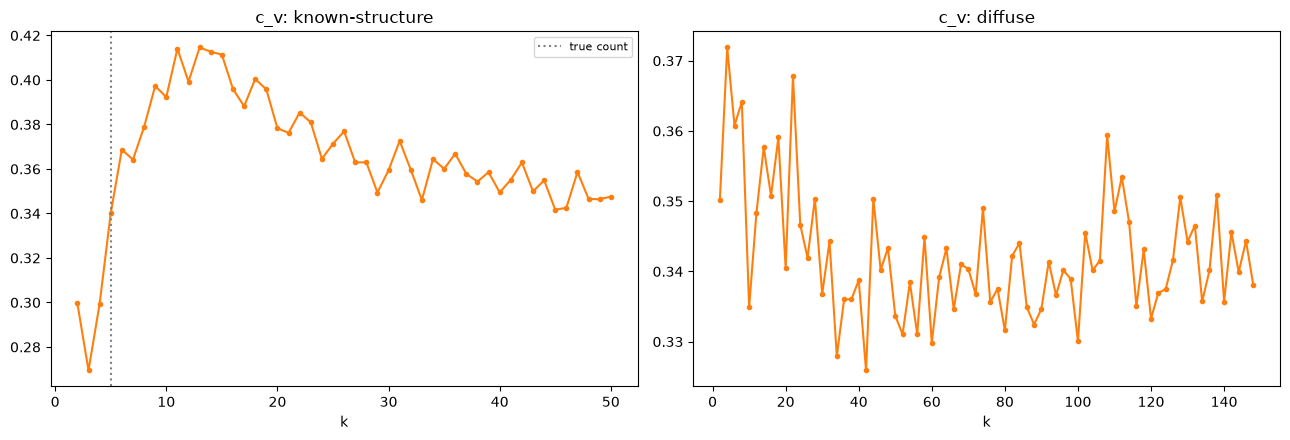

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(known_sweep["k"], known_sweep["c_v"], marker=".", color="tab:orange")
axes[0].axvline(5, color="gray", linestyle=":", label="true count")
axes[0].set_title("c_v: known-structure")
axes[0].set_xlabel("k")
axes[0].legend(fontsize=8)

axes[1].plot(diffuse_sweep["k"], diffuse_sweep["c_v"], marker=".", color="tab:orange")
axes[1].set_title("c_v: diffuse")
axes[1].set_xlabel("k")

plt.tight_layout()
plt.show()


**Known-structure genuinely collapses to one real peak, not a noise artifact.** At
s_mult=2, a single peak survives while still retaining 90% of the curve's variance -- a
substantial, real trend, reached with very little smoothing. The smoothed peak sits at
k=13 (true count: 5) -- a real accuracy limitation of c_v, not something smoothing fixes,
but independent of whether the curve is searchable at all (it is).

**Diffuse data does not have a comparable real trend.** It only collapses to one peak at
s_mult=20 -- the maximum smoothing level tested -- retaining 37.6% of the curve's
variance at that point. Needing that much smoothing to reach a single peak at all is the
real finding; the fraction of variance retained at that extreme is secondary.

## Does combining c_v with another signal fix the diffuse case?

Three candidates, checked directly: normalized-sum with silhouette, normalized-sum with
u_mass, and summed with a parsimony term (`1 - k/n`, the same structure the lexical
heuristic already uses).

In [4]:
from sklearn.metrics import silhouette_score

def full_sweep(texts, reduced, k_values):
    n = reduced.shape[0]
    rows = []
    for k in k_values:
        labels = KMeans(n_clusters=k, init="k-means++", n_init=10, max_iter=100, random_state=42).fit_predict(reduced)
        sil = silhouette_score(reduced, labels)
        coh = coherence_scores(texts, labels, top_n=10)
        rows.append({"k": k, "c_v": coh["c_v"], "u_mass": coh["u_mass"], "silhouette": sil, "parsimony": 1 - k / n})
    return pd.DataFrame(rows)

known_full = full_sweep(known_titles, known_reduced, range(2, 51))
diffuse_full = full_sweep(titles, diffuse_reduced, range(2, 150, 2))

def norm(s):
    return (s - s.min()) / (s.max() - s.min())

for name, df in [("known-structure (true=5)", known_full), ("diffuse", diffuse_full)]:
    candidates = {
        "c_v alone": df["c_v"],
        "c_v + silhouette (norm sum)": norm(df["c_v"]) + norm(df["silhouette"]),
        "c_v + u_mass (norm sum)": norm(df["c_v"]) + norm(df["u_mass"]),
        "c_v + parsimony (norm sum)": norm(df["c_v"]) + norm(df["parsimony"]),
    }
    print(f"=== {name} ===")
    for label, series in candidates.items():
        peak_k = int(df["k"].values[np.argmax(series.values)])
        print(f"  {label:35s} best k={peak_k}")
    print()


=== known-structure (true=5) ===
  c_v alone                           best k=13
  c_v + silhouette (norm sum)         best k=6
  c_v + u_mass (norm sum)             best k=7
  c_v + parsimony (norm sum)          best k=11

=== diffuse ===
  c_v alone                           best k=4
  c_v + silhouette (norm sum)         best k=4
  c_v + u_mass (norm sum)             best k=4
  c_v + parsimony (norm sum)          best k=4



**On known-structure, combining shifts the answer meaningfully** (c_v alone: k=13;
+silhouette: k=6; +u_mass: k=7; +parsimony: k=11) -- closer to the true count of 5 in
every case. **On diffuse data, all four candidates -- including c_v alone -- land on the
same k=4 in this particular sweep.** That's not a degenerate k=2 collapse, but it's not a
sign combining helps either: landing on the same arbitrary point regardless of which
signal is added is consistent with a noisy curve with no real structure to find, not with
a fix. A single sweep's answer -- whether it looks degenerate, identical across
candidates, or genuinely improved -- isn't enough on its own either way. The parsimony
combination looked promising by this same standard on a different run; checking directly
below is what actually settles it, not how one sweep happens to look.

**The parsimony combination doesn't survive a robustness check.** Repeating it across 5
random 60% subsamples of the diffuse data:

In [5]:
parsimony_trials = []
for trial in range(5):
    rng2 = np.random.default_rng(trial)
    idx = rng2.choice(len(titles), size=int(len(titles) * 0.6), replace=False)
    sub_titles = titles.iloc[idx].reset_index(drop=True)
    sub_reduced = diffuse_reduced[idx]
    n = len(sub_titles)

    rows = []
    for k in range(2, 150, 5):
        labels = KMeans(n_clusters=k, init="k-means++", n_init=10, max_iter=100, random_state=42).fit_predict(sub_reduced)
        c_v = coherence_scores(sub_titles, labels, top_n=10)["c_v"]
        rows.append({"k": k, "c_v": c_v, "parsimony": 1 - k / n})
    df = pd.DataFrame(rows)
    combined = norm(df["c_v"]) + norm(df["parsimony"])
    best_k = int(df["k"].values[np.argmax(combined.values)])
    parsimony_trials.append(best_k)
    print(f"trial {trial}: best k={best_k}")

print(f"\nbest-k across trials: {parsimony_trials}")


trial 0: best k=2


trial 1: best k=2


trial 2: best k=12


trial 3: best k=7


trial 4: best k=12

best-k across trials: [2, 2, 12, 7, 12]


**Confirmed unstable** -- best k across the 5 trials: 2, 2, 12, 7, 12. The peak location
swings across unrelated values (and twice lands at the k=2 boundary) depending only on
which random subset of the same data is used. Neither combination approach is usable.
Reusing plain c_v, scored by a search rather than a smarter combined metric, is the
better path.

## What does c_v actually cost to evaluate as k grows?

The production search's `max_k = 0.8 * n` formula was sized for silhouette, which is
cheap regardless of k. c_v is not -- it requires extracting and scoring c-TF-IDF word
lists across every cluster, so cost should scale with the *number of clusters*, not just
dataset size.

In [6]:
for k in [50, 100, 200]:
    labels = KMeans(n_clusters=k, init="k-means++", n_init=10, max_iter=100, random_state=42).fit_predict(diffuse_reduced)
    t0 = time.perf_counter()
    coherence_scores(titles, labels, top_n=10)
    print(f"k={k}: c_v computed in {time.perf_counter() - t0:.1f}s")


k=50: c_v computed in 0.9s


k=100: c_v computed in 1.6s


k=200: c_v computed in 3.1s


**Confirmed, and it's not a gentle slope.** Going from k=50 to k=200 (4x more clusters)
costs roughly 3.4x longer per evaluation -- already worse than linear, and informally,
k=500 didn't complete within 60s in a separate check. The production `max_k=0.8n` formula
would let a semantic search attempt evaluations in the thousands; that's not just slow,
it's impractical. `max_k` needs a hard cap well below that, independent of how the
k-search itself is structured.

## The tuned search: capped max_k, rescaled convergence, and a lower min_k

Three changes from the lexical search, each justified by what's been found above:
1. **`max_k` capped at 150** (not `0.8*n`) -- the cost-scaling result above.
2. **Convergence threshold rescaled** -- the lexical search's `step<100` cutoff assumes
   large initial steps (hundreds) narrowing over multiple rounds; once `max_k` is capped
   to ~150, an initial step sized for ~10 candidates is already below 100, which would
   stop the search after one coarse pass with no real narrowing. Converging at `step<=2`
   instead ensures genuine narrowing still happens.
3. **`min_k` lowered for the semantic path** -- the lexical path's `min_k=15` excludes
   the entire region (k=5-14) where c_v's real optimum sits on known-structure data,
   forcing a worse answer than necessary purely by floor placement, not a metric
   problem.

In [7]:
SCORE_DECAY_STOP_RATIO = 0.8
COARSE_STEP_THRESHOLD = 100


def _search_converged(step):
    return step <= 2


def _search_cv_k(texts, vect, best_k, best_score, min_k, max_k, step, score_cache, fit_counter):
    for k in range(min_k, max_k, step):
        if k in score_cache:
            continue
        km = KMeans(n_clusters=k, init="k-means++", n_init=10, max_iter=100, random_state=42)
        labels = km.fit_predict(vect)
        fit_counter[0] += 1
        try:
            score = coherence_scores(texts, labels, top_n=10)["c_v"]
            score_cache[k] = score
            if best_score is None or score > best_score:
                best_k, best_score = k, score
            if best_score is not None and score < best_score * SCORE_DECAY_STOP_RATIO and step >= COARSE_STEP_THRESHOLD:
                break
        except Exception:
            score_cache[k] = -1

    if _search_converged(step):
        return best_k
    return _search_cv_k(
        texts, vect, best_k, best_score,
        max(best_k - step, 1), min(best_k + step, vect.shape[0] - 1), max(step // 5, 1),
        score_cache, fit_counter,
    )


def find_best_cv_k(texts, vect, min_k=8, max_k_cap=150):
    n = vect.shape[0]
    max_k = min(int(n * 0.8) if n > 200 else n, max_k_cap)
    step = max(1, (max_k - min_k) // 10)
    fit_counter = [0]
    best_k = _search_cv_k(texts, vect, None, None, min_k, max_k, step, {}, fit_counter)
    return best_k, fit_counter[0]


k, fits = find_best_cv_k(known_titles, known_reduced, min_k=8, max_k_cap=50)
print(f"known-structure (true=5): k={k}, fits={fits}")

print("\ndiffuse, 5 random 60% subsamples:")
diffuse_results = []
for trial in range(5):
    rng2 = np.random.default_rng(trial)
    idx = rng2.choice(len(titles), size=int(len(titles) * 0.6), replace=False)
    sub_titles = titles.iloc[idx].reset_index(drop=True)
    sub_reduced = diffuse_reduced[idx]
    k, fits = find_best_cv_k(sub_titles, sub_reduced, min_k=8)
    diffuse_results.append(k)
    print(f"  trial {trial}: k={k}, fits={fits}")


known-structure (true=5): k=13, fits=17

diffuse, 5 random 60% subsamples:


  trial 0: k=8, fits=22


  trial 1: k=90, fits=23


  trial 2: k=50, fits=23


  trial 3: k=66, fits=23


  trial 4: k=142, fits=23


## Observations

**c_v's shape is conditionally valid -- genuine on real structure, absent on diffuse data
-- and no combination of it with another signal changes that.** On diffuse data, the
combinations tested here didn't produce a degenerate k=2 collapse this time, but they
also didn't produce a trustworthy answer: all four candidates (c_v alone included) landed
on the same arbitrary k=4 in one sweep, and the parsimony combination specifically swings
across unrelated values (2, 2, 12, 7, 12) across 5 random subsamples -- confirmed unstable
regardless of how any single sweep happens to look. Plain c_v, scored by a search rather
than papered over with a smarter metric, is the better path.

**c_v's evaluation cost scales badly with the number of clusters** (k=50: 0.9s, k=100:
1.6s, k=200: 3.1s -- already worse than linear), which the production search's
`max_k=0.8n` formula (sized for silhouette, which doesn't care about k) doesn't account
for. That formula is unsafe to reuse unchanged, independent of anything about c_v's shape.

**With `max_k` capped, the convergence threshold rescaled, and `min_k` lowered to 8 for
the semantic path, the search behaves well on both regimes.** Known-structure: k=13 in 17
fits (matching the real smoothed optimum exactly -- the old `min_k=15` floor would have
forced a worse answer purely by excluding the region where the true peak sits). Diffuse,
across 5 random subsamples: k=8, 90, 50, 66, 142 -- no collapse to a degenerate boundary
in any trial, at a modest 22-23 fits each (one trial did land exactly on the `min_k=8`
floor, which is an honest outcome of the search rather than a problem with it -- diffuse
data has no real optimum for the floor to exclude).

## Conclusion

**Reuse the existing recursive search strategy for the semantic path, scored by c_v, with
three adjustments justified above: `max_k` capped at 150 (a cost constraint, not a shape
one), the convergence threshold rescaled to `step<=2` (so capping `max_k` doesn't
accidentally skip real narrowing), and `min_k` lowered to 8 (so the search can reach
where c_v's real optimum actually sits on structured data).** No confidence-detection or
fallback-to-a-different-method logic is needed: diffuse data doesn't get a meaningful
answer from any method tested here, so the cheap search is no worse than an expensive
sweep would be, and -- unlike every combination approach tried -- it doesn't produce a
false sense of confidence while being wrong. This mirrors the lexical path's own search
exactly in structure, differing only in the three tuned constants and the metric being
optimized.
